# ShopperIntent — Düzeltilmiş PyTorch deneyleri

Bu notebook mevcut **%70 / %15 / %15** veri ayrımını korur. 73 giriş özelliği ile 64 → 32 → 2 MLP kurar. **ReLU + Adam**, **GELU + Adam** ve **ReLU + SGD** deneyleri tamamen ayrı model/optimizer nesneleriyle ve **15 epoch, LR=0.001, seed=42** ile gerçekleştirilir.

**Önemli:** Önceki notebook'ta `train_loader` değişken adı hatası vardı; ayrıca üç deneyin ve değerlendirme kodunun kayıtlı hücreleri yoktu. Düzenlenen sürümde sonuçlar her model için ayrı hesaplanır. **Bağımsız test kümesi kullanılmaz.**

`notebooks/` dizininden **Restart & Run All** çalıştır; CSV dosyası `../data/online_shoppers_intention.csv` konumunda olmalı.

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler , LabelEncoder , OneHotEncoder 
from sklearn.compose import ColumnTransformer

import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

# Model parametrelerinin başlangıcı için seed (tam determinism garanti etmez).
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
import time
import random
from pathlib import Path


Device: cuda


In [3]:
df = pd.read_csv("../data/online_shoppers_intention.csv")
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [4]:
# Hedef: Revenue=True (1); PageValues dışarıda tutulur.
y = df["Revenue"].astype(int)
X = df.drop(columns=["Revenue", "PageValues"])
assert "PageValues" not in X.columns and "Revenue" not in X.columns

In [5]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

In [6]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [7]:
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (8631, 16)
Validation: (1849, 16)
Test: (1850, 16)


In [8]:
cat_cols = [
    "Month",
    "VisitorType",
    "Weekend",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType"
]

target = "Revenue"

num_cols = [
    col for col in X_train.columns
    if col not in cat_cols + [target]
]

print("Categorical:", cat_cols)
print("Numerical:", num_cols)

Categorical: ['Month', 'VisitorType', 'Weekend', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']
Numerical: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'SpecialDay']


In [9]:
one_hot_cols = [col for col in cat_cols if X_train[col].nunique() > 2]
binary_cols = [col for col in cat_cols if col not in one_hot_cols]


In [10]:
# Tüm özellikler açıkça tanımlandı: sadece binary sütunlar passthrough.
tranformer = ColumnTransformer(
    transformers=[
        ("stnd_scaler", StandardScaler(), num_cols),
        ("one_hot", OneHotEncoder(handle_unknown="ignore"), one_hot_cols),
        ("binary", "passthrough", binary_cols),
    ],
    remainder="drop",
)
pipline = Pipeline(steps=[("tranformer", tranformer)])

In [11]:
# Yalnızca train üzerinde fit; validation üzerinde sadece transform.
x_train_tranformer = pipline.fit_transform(X_train)
X_val_tranformer = pipline.transform(X_val)
# Test kümesi son değerlendirmeye kadar kullanılmayacak.

In [12]:
def to_dense(matrix):
    # ColumnTransformer sparse veya dense döndürebilir.
    return matrix.toarray() if hasattr(matrix, "toarray") else np.asarray(matrix)

X_train_tensor = torch.tensor(to_dense(x_train_tranformer), dtype=torch.float32)
X_val_tensor = torch.tensor(to_dense(X_val_tranformer), dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.to_numpy(), dtype=torch.long)
y_val_tensor = torch.tensor(y_val.to_numpy(), dtype=torch.long)

input_dim = X_train_tensor.shape[1]
assert input_dim == X_val_tensor.shape[1]
print("Encoded feature count:", input_dim)

Encoded feature count: 73


In [13]:
print(X_train_tensor.shape)
print(X_train_tensor.dtype)

print(X_val_tensor.shape)
print(X_val_tensor.dtype)

torch.Size([8631, 73])
torch.float32
torch.Size([1849, 73])
torch.float32


In [14]:
dataset_train = TensorDataset(X_train_tensor , y_train_tensor)

dataloader_train = DataLoader(dataset=dataset_train , batch_size=32 , shuffle=True)

len(dataloader_train)

270

In [15]:
dataset_val = TensorDataset(X_val_tensor , y_val_tensor)

dataloader_val = DataLoader(dataset=dataset_val , batch_size=32)

len(dataloader_val)

58

In [16]:
class ShopperClassifier(nn.Module):
    def __init__(self, activation="relu", input_dim=73):
        super().__init__()
        if activation == "relu":
            activation_layer = nn.ReLU
        elif activation == "gelu":
            activation_layer = nn.GELU
        else:
            raise ValueError("Activation must be 'relu' or 'gelu'")

        self.linear_layer = nn.Sequential(
            nn.Linear(input_dim, 64),
            activation_layer(),
            nn.Linear(64, 32),
            activation_layer(),
            nn.Linear(32, 2),
        )

    def forward(self, x):
        return self.linear_layer(x)  # Ham logits; CrossEntropyLoss öncesi Softmax yok.


In [17]:
model_relu = ShopperClassifier(activation="relu", input_dim=input_dim)
total_params = sum(p.numel() for p in model_relu.parameters() if p.requires_grad)
print("Total trainable parameters:", total_params)
assert total_params == 6882
print("Model output shape:", model_relu(X_train_tensor[:32]).shape)

Total trainable parameters: 6882
Model output shape: torch.Size([32, 2])


In [ ]:
# Kayıp fonksiyonu; optimizer her deneyde yeniden oluşturulacak.
criterion = nn.CrossEntropyLoss()

In [19]:
def train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs
):
    train_losses = []
    val_losses = []

    for epoch in range(epochs):

        # ============================
        # TRAINING
        # ============================

        model.train()

        running_loss = 0.0
        total_samples = 0

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(next(model.parameters()).device)
            y_batch = y_batch.to(next(model.parameters()).device)

            # 1. Gradyanları sıfırla
            optimizer.zero_grad()

            # 2. Forward Pass
            outputs = model(X_batch)

            # 3. Loss hesapla
            loss = criterion(outputs, y_batch)

            # 4. Backward Pass
            loss.backward()

            # 5. Ağırlıkları güncelle
            optimizer.step()

            # 6. Batch loss değerini biriktir
            batch_size = y_batch.size(0)

            running_loss += loss.item() * batch_size
            total_samples += batch_size

        # Epoch ortalama training loss
        epoch_train_loss = running_loss / total_samples

        train_losses.append(epoch_train_loss)

        # ============================
        # VALIDATION
        # ============================

        model.eval()

        val_running_loss = 0.0
        val_total_samples = 0

        with torch.no_grad():

            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(next(model.parameters()).device)
                y_batch = y_batch.to(next(model.parameters()).device)

                # Forward Pass
                outputs = model(X_batch)

                # Validation Loss
                loss = criterion(outputs, y_batch)

                # Loss değerlerini biriktir
                batch_size = y_batch.size(0)

                val_running_loss += loss.item() * batch_size
                val_total_samples += batch_size

        # Epoch ortalama validation loss
        epoch_val_loss = val_running_loss / val_total_samples

        val_losses.append(epoch_val_loss)

        # ============================
        # EPOCH SONUÇLARI
        # ============================

        print(
            f"Epoch [{epoch+1}/{epochs}] | "
            f"Train Loss: {epoch_train_loss:.4f} | "
            f"Val Loss: {epoch_val_loss:.4f}"
        )

    return {
        "train_loss": train_losses,
        "val_loss": val_losses
    }

In [20]:
# Kontrol: son eğitim hücresindeki hatalı train_loader adı giderildi.
# Deney koşulları aynı olacak; her deney ayrı model ve optimizer kuracak.
SEED = 42
LR = 0.001
EPOCHS = 15
BATCH_SIZE = 32


def run_experiment(experiment_id, activation, optimizer_name):
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    # Her deney için YENİ model ve optimizer.
    model = ShopperClassifier(activation=activation, input_dim=input_dim).to(device)
    if optimizer_name == "Adam":
        optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    elif optimizer_name == "SGD":
        optimizer = torch.optim.SGD(model.parameters(), lr=LR)
    else:
        raise ValueError("Optimizer Adam veya SGD olmalı")

    # Her deneyde aynı batch karıştırma düzeni.
    train_loader = DataLoader(
        dataset_train, batch_size=BATCH_SIZE, shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    )

    if device.type == "cuda":
        torch.cuda.synchronize()
    start_time = time.perf_counter()
    history = train_model(
        model=model,
        train_loader=train_loader,
        val_loader=dataloader_val,
        criterion=criterion,
        optimizer=optimizer,
        epochs=EPOCHS,
    )
    if device.type == "cuda":
        torch.cuda.synchronize()

    return {
        "experiment_id": experiment_id,
        "activation": activation,
        "optimizer": optimizer_name,
        "model": model,
        "history": history,
        "training_time": time.perf_counter() - start_time,
    }

## Görev 4 — Üç bağımsız deney

ReLU↔GELU karşılaştırmasında yalnızca aktivasyon, Adam↔SGD karşılaştırmasında yalnızca optimizer değişir.

In [21]:
experiment_a = run_experiment("MLP-A", "relu", "Adam")
experiment_b = run_experiment("MLP-B", "gelu", "Adam")
experiment_c = run_experiment("MLP-C", "relu", "SGD")

assert len({id(experiment_a["model"]), id(experiment_b["model"]), id(experiment_c["model"])}) == 3
print("Üç model farklı nesneler: OK")

Epoch [1/15] | Train Loss: 0.4015 | Val Loss: 0.3788
Epoch [2/15] | Train Loss: 0.3694 | Val Loss: 0.3747
Epoch [3/15] | Train Loss: 0.3635 | Val Loss: 0.3770
Epoch [4/15] | Train Loss: 0.3588 | Val Loss: 0.3769
Epoch [5/15] | Train Loss: 0.3544 | Val Loss: 0.3760
Epoch [6/15] | Train Loss: 0.3493 | Val Loss: 0.3791
Epoch [7/15] | Train Loss: 0.3457 | Val Loss: 0.3830
Epoch [8/15] | Train Loss: 0.3388 | Val Loss: 0.3820
Epoch [9/15] | Train Loss: 0.3337 | Val Loss: 0.3840
Epoch [10/15] | Train Loss: 0.3296 | Val Loss: 0.3874
Epoch [11/15] | Train Loss: 0.3231 | Val Loss: 0.3918
Epoch [12/15] | Train Loss: 0.3198 | Val Loss: 0.3945
Epoch [13/15] | Train Loss: 0.3141 | Val Loss: 0.4012
Epoch [14/15] | Train Loss: 0.3076 | Val Loss: 0.4060
Epoch [15/15] | Train Loss: 0.3015 | Val Loss: 0.4156
Epoch [1/15] | Train Loss: 0.4040 | Val Loss: 0.3784
Epoch [2/15] | Train Loss: 0.3725 | Val Loss: 0.3754
Epoch [3/15] | Train Loss: 0.3692 | Val Loss: 0.3785
Epoch [4/15] | Train Loss: 0.3669 | Val 

### Validation metrikleri

`argmax(logits)` → sınıf etiketi; `softmax(logits)[:, 1]` → **Revenue=True** olasılığı. Average Precision hesabında sınıf etiketi yerine pozitif sınıf olasılığı kullanılır.

In [22]:
def evaluate_model(model, val_loader):
    model.eval()
    current_device = next(model.parameters()).device
    y_true, y_pred, y_proba = [], [], []

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            logits = model(X_batch.to(current_device))
            probs = torch.softmax(logits, dim=1)[:, 1]
            predictions = logits.argmax(dim=1)
            y_true.extend(y_batch.cpu().tolist())
            y_pred.extend(predictions.cpu().tolist())
            y_proba.extend(probs.cpu().tolist())

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "f1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "average_precision": average_precision_score(y_true, y_proba),
    }

results = []
for experiment in (experiment_a, experiment_b, experiment_c):
    # KRİTİK: Değerlendirilen model, bu deneyin kendi modelidir!
    metrics = evaluate_model(experiment["model"], dataloader_val)
    results.append({
        "experiment_id": experiment["experiment_id"],
        "activation": experiment["activation"],
        "optimizer": experiment["optimizer"],
        "learning_rate": LR,
        "epochs": EPOCHS,
        "seed": SEED,
        "training_time": experiment["training_time"],
        "train_loss": experiment["history"]["train_loss"][-1],
        "validation_loss": experiment["history"]["val_loss"][-1],
        **metrics,
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,experiment_id,activation,optimizer,learning_rate,epochs,seed,training_time,train_loss,validation_loss,accuracy,precision,recall,f1,average_precision
0,MLP-A,relu,Adam,0.001,15,42,4.1645,0.3015,0.4156,0.8378,0.4146,0.1189,0.1848,0.3161
1,MLP-B,gelu,Adam,0.001,15,42,3.3818,0.3405,0.3826,0.8415,0.4255,0.0699,0.1201,0.3354
2,MLP-C,relu,SGD,0.001,15,42,3.2683,0.4177,0.4188,0.8453,0.0000,0.0000,0.0000,0.2453


## Sonuçları kaydet ve loss eğrilerini incele

CSV kaydedildi: ../reports/optimizer_ablation.csv
Loss geçmişi kaydedildi: ../reports/loss_history.csv


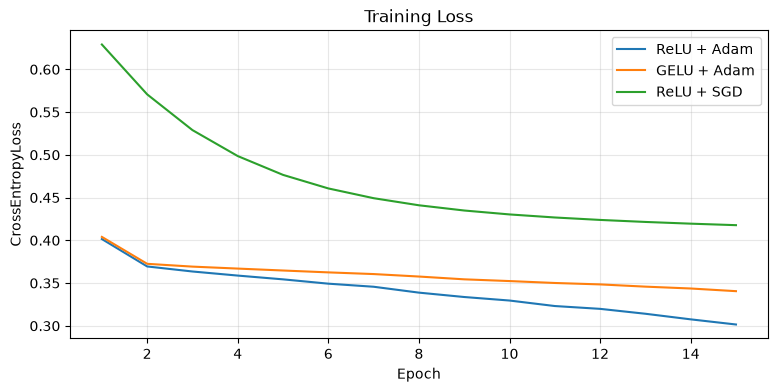

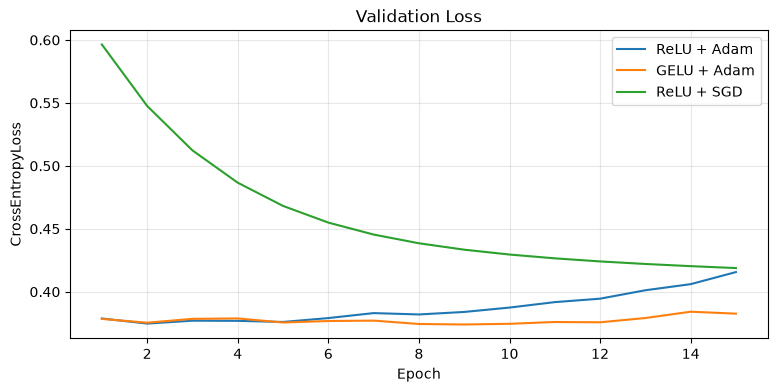

In [23]:
loss_history_df = pd.DataFrame({
    "epoch": range(1, EPOCHS + 1),
    "relu_adam_train": experiment_a["history"]["train_loss"],
    "relu_adam_val": experiment_a["history"]["val_loss"],
    "gelu_adam_train": experiment_b["history"]["train_loss"],
    "gelu_adam_val": experiment_b["history"]["val_loss"],
    "relu_sgd_train": experiment_c["history"]["train_loss"],
    "relu_sgd_val": experiment_c["history"]["val_loss"],
})
reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)
results_df.to_csv(reports_dir / "optimizer_ablation.csv", index=False)
loss_history_df.to_csv(reports_dir / "loss_history.csv", index=False)
print("CSV kaydedildi:", reports_dir / "optimizer_ablation.csv")
print("Loss geçmişi kaydedildi:", reports_dir / "loss_history.csv")

for series, title in [("train", "Training Loss"), ("val", "Validation Loss")]:
    plt.figure(figsize=(9, 4))
    for key, label in [("relu_adam", "ReLU + Adam"), ("gelu_adam", "GELU + Adam"), ("relu_sgd", "ReLU + SGD")]:
        plt.plot(loss_history_df["epoch"], loss_history_df[f"{key}_{series}"], label=label)
    plt.xlabel("Epoch")
    plt.ylabel("CrossEntropyLoss")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()